In [ ]:
import torch
import torch.nn as nn
import torchvision.models as models

resnet50 = models.resnet50(pretrained=False)
num_features = resnet50.fc.in_features
resnet50.fc = nn.Linear(num_features, 10)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [ ]:
import torch.nn.functional as F

class Bottleneck(nn.Module):
  expansion = 4
  def __init__(self,in_channels, out_channels, stride =1, downsample = None):
    super(Bottleneck, self).__init__()

    self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size = 1,bias = False)
    self.bn1 = nn.BatchNorm2d(out_channels)

    self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = stride, padding = 1, bias = False)
    self.bn2 = nn.BatchNorm2d(out_channels)

    self.conv3 = nn.Conv2d(out_channels, out_channels * self.expansion, kernel_size = 1, bias = False)
    self.bn3 = nn.BatchNorm2d(out_channels * self.expansion)

    self.relu = nn.ReLU(inplace = True)
    self.downsample = downsample

  def forward(self,x):
    identity = x

    out = self.conv1(x)
    out = self.bn1(out)
    out = self.relu(out)

    out = self.conv2(out)
    out = self.bn2(out)
    out = self.relu(out)

    out = self.conv3(out)
    out = self.bn3(out)

    if self.downsample is not None:
      identity = self.downsample(x)
    out += identity
    out = self.relu(out)

    return out

In [ ]:
class MyResNet50(nn.Module):
  def __init__(self, num_classes = 1000):
    super(MyResNet50, self).__init__()

    self.conv1 = nn.Conv2d(3,64, kernel_size = 7, stride =2, padding =3, bias = False)
    self.bn1 = nn.BatchNorm2d(64)
    self.relu = nn.ReLU(inplace = True)
    self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)

    self.inplanes = 64

    self.layer1 = self._make_layer(Bottleneck, 64,  3, stride=1)
    self.layer2 = self._make_layer(Bottleneck, 128, 4, stride=2)
    self.layer3 = self._make_layer(Bottleneck, 256, 6, stride=2)
    self.layer4 = self._make_layer(Bottleneck, 512, 3, stride=2)

    self.avgpool = nn.AdaptiveAvgPool2d((1,1))
    self.fc = nn.Linear(512 * Bottleneck.expansion, num_classes)

  def _make_layer(self, block, out_channels, blocks, stride = 1):
    downsample = None

    if stride != 1 or self.inplanes != out_channels * block.expansion:
      downsample = nn.Sequential(
          nn.Conv2d(self.inplanes, out_channels * block.expansion, kernel_size =1, stride = stride, bias = False),
          nn.BatchNorm2d(out_channels * block.expansion)
      )
    layers = []
    layers.append(block(self.inplanes, out_channels, stride, downsample))
    self.inplanes = out_channels * block.expansion

    for _ in range(1, blocks):
      layers.append(block(self.inplanes, out_channels))

    return nn.Sequential(*layers)

  def forward(self, x):
    x = self.conv1(x)
    x = self.bn1(x)
    x = self.relu(x)
    x = self.maxpool(x)

    x = self.layer1(x)
    x = self.layer2(x)
    x = self.layer3(x)
    x = self.layer4(x)

    x = self.avgpool(x)
    x = torch.flatten(x, 1)
    x = self.fc(x)
    return x

In [ ]:
model = MyResNet50(num_classes = 1000)
model

MyResNet50(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=

In [ ]:
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
from tqdm import tqdm
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform_train)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=128,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform_test)
testloader = torch.utils.data.DataLoader(testset, batch_size=100,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')


100%|██████████| 170M/170M [00:14<00:00, 11.7MB/s]


In [ ]:
model = MyResNet50(num_classes=10).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=5e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=200)

print(f"Model initialized with {10} classes and moved to {device}.")

Model initialized with 10 classes and moved to cuda.


In [ ]:
def train(epoch):
    print(f'\nEpoch: {epoch}')
    model.train()
    train_loss = 0
    correct = 0
    total = 0
    for batch_idx, (inputs, targets) in enumerate(tqdm(trainloader, desc='Training')):
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()

    print(f'Training Loss: {train_loss/(batch_idx+1):.3f} | Acc: {100.*correct/total:.3f}% ({correct}/{total})')


In [ ]:
def test(epoch):
    model.eval()
    test_loss = 0
    correct = 0
    total = 0
    all_preds = []
    all_targets = []
    with torch.no_grad():
        for batch_idx, (inputs, targets) in enumerate(tqdm(testloader, desc='Testing')):
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)

            test_loss += loss.item()
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

    print(f'Test Loss: {test_loss/(batch_idx+1):.3f} | Acc: {100.*correct/total:.3f}% ({correct}/{total})')
    return np.array(all_targets), np.array(all_preds)


Epoch: 0


Training: 100%|██████████| 391/391 [00:44<00:00,  8.69it/s]


Training Loss: 2.527 | Acc: 26.680% (13340/50000)


Testing: 100%|██████████| 100/100 [00:03<00:00, 32.34it/s]


Test Loss: 7.022 | Acc: 29.920% (2992/10000)

Epoch: 1


Training: 100%|██████████| 391/391 [00:40<00:00,  9.65it/s]


... (31 outputs left out)

Training: 100%|██████████| 391/391 [00:41<00:00,  9.47it/s]


Training Loss: 1.332 | Acc: 55.478% (27739/50000)


Testing: 100%|██████████| 100/100 [00:03<00:00, 31.34it/s]


Test Loss: 2.591 | Acc: 58.410% (5841/10000)


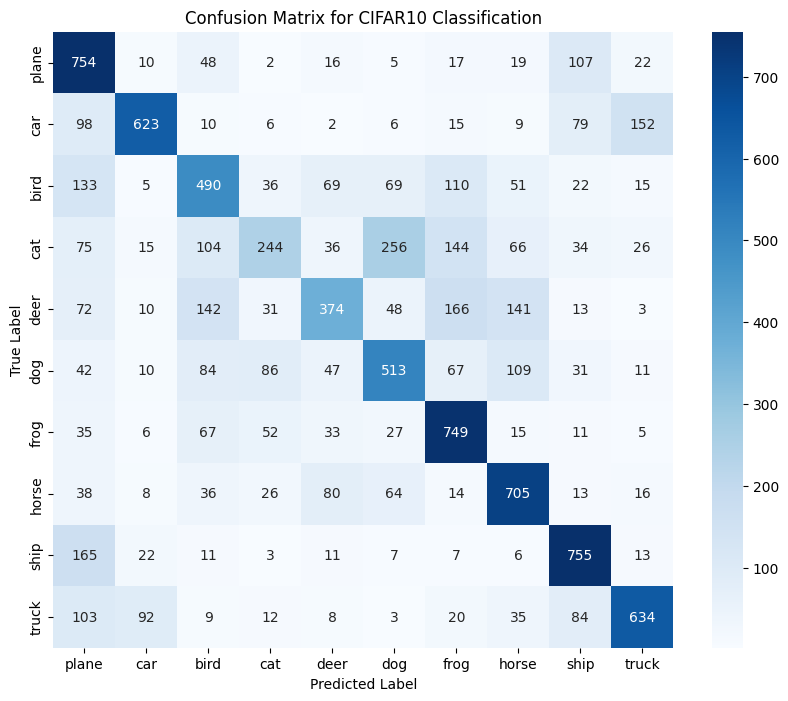

In [ ]:
epochs = 10 # You can adjust the number of epochs

for epoch in range(epochs):
    train(epoch)
    targets, preds = test(epoch)
    scheduler.step()

# Calculate Confusion Matrix
cm = confusion_matrix(targets, preds)

# Plot Confusion Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for CIFAR10 Classification')
plt.show()